# Titanic Survival - Exploratory Data Analysis
**Author:** Vaishnavi Kelkar

Analyzing the Titanic passenger dataset to understand what factors influenced survival: gender, class, age, and fare.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('titanic.csv')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 1. Data Cleaning

In [2]:
print(df.shape)
print(df.isnull().sum())

(891, 15)
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [3]:
# Fill missing age with median, drop deck (too many missing), fill embark_town with mode
df['age'] = df['age'].fillna(df['age'].median())
df = df.drop(columns=['deck'])
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])
df = df.drop_duplicates()
df.isnull().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       2
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

## 2. Survival Rate Overview

Overall survival rate: 41.29%


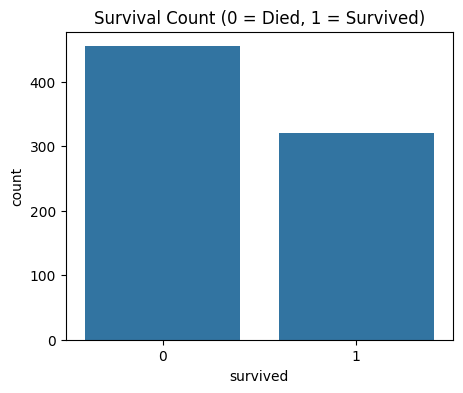

In [4]:
survival_rate = df['survived'].mean() * 100
print(f'Overall survival rate: {survival_rate:.2f}%')

plt.figure(figsize=(5,4))
sns.countplot(x='survived', data=df)
plt.title('Survival Count (0 = Died, 1 = Survived)')
plt.savefig('chart_survival_count.png')
plt.show()

## 3. Survival by Gender

sex
female    73.972603
male      21.532091
Name: survived, dtype: float64


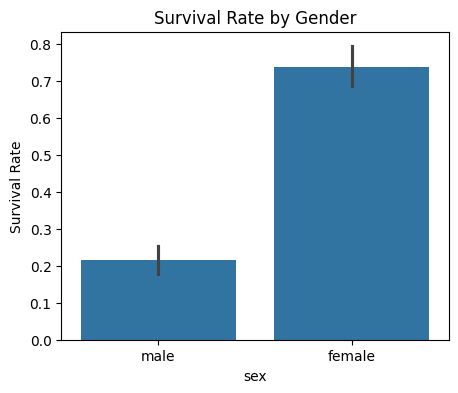

In [5]:
gender_survival = df.groupby('sex')['survived'].mean() * 100
print(gender_survival)

plt.figure(figsize=(5,4))
sns.barplot(x='sex', y='survived', data=df)
plt.title('Survival Rate by Gender')
plt.ylabel('Survival Rate')
plt.savefig('chart_gender_survival.png')
plt.show()

## 4. Survival by Passenger Class

pclass
1    63.333333
2    50.609756
3    25.935162
Name: survived, dtype: float64


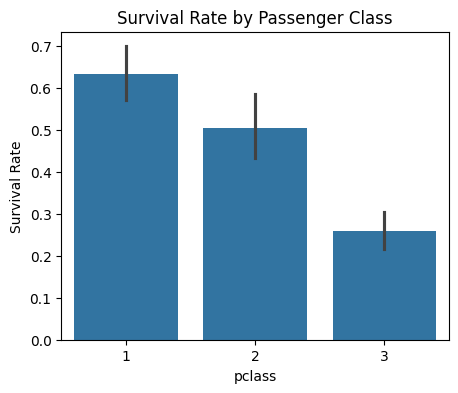

In [6]:
class_survival = df.groupby('pclass')['survived'].mean() * 100
print(class_survival)

plt.figure(figsize=(5,4))
sns.barplot(x='pclass', y='survived', data=df)
plt.title('Survival Rate by Passenger Class')
plt.ylabel('Survival Rate')
plt.savefig('chart_class_survival.png')
plt.show()

## 5. Age Distribution by Survival

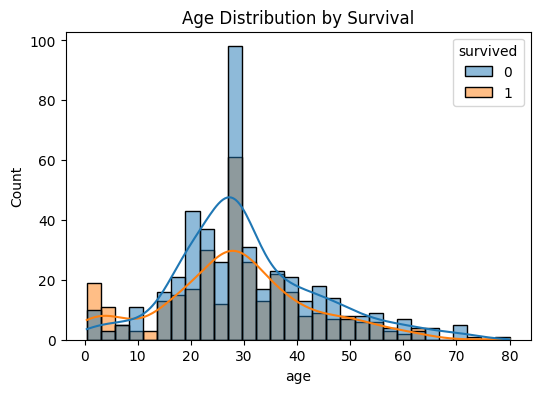

In [7]:
plt.figure(figsize=(6,4))
sns.histplot(data=df, x='age', hue='survived', bins=30, kde=True)
plt.title('Age Distribution by Survival')
plt.savefig('chart_age_distribution.png')
plt.show()

## 6. Fare vs Survival

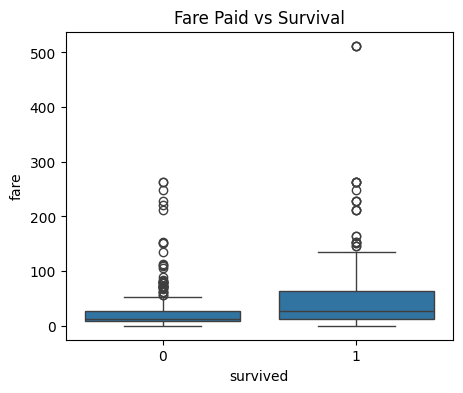

In [8]:
plt.figure(figsize=(5,4))
sns.boxplot(x='survived', y='fare', data=df)
plt.title('Fare Paid vs Survival')
plt.savefig('chart_fare_survival.png')
plt.show()

## Key Insights
- Overall survival rate was around 38%.
- Females had a much higher survival rate (~74%) than males (~19%) — consistent with 'women and children first' boarding policy.
- 1st class passengers survived at a much higher rate (~63%) than 3rd class (~24%), showing class privilege affected survival chances.
- Passengers who paid higher fares (correlated with 1st class) had better survival odds.
- Younger passengers (children) had a slightly higher survival rate within the age distribution.